# wPINN: L0, L1 y L2, con y sin corrección, con la mejor configuración (choque móvil, T = 1)

Ley de conservación de Burgers en 2D,
$u_t + \partial_x(u^2/2) + \partial_y(u^2/2) = 0$ en $[-1,1]^2 \times [0, T]$ con $T = 1$, y $u_0 = 1$ si
$x \le 0$, $u_0 = 0$ si $x > 0$. La solución es un choque que viaja a velocidad $1/2$: en $t = T$ está
en $x = 0.5$.

Cinco simulaciones (semilla 0, 5000 épocas cada una):

- **L0**;
- **L1 y L2 tal como están en el paper** (ec. 11 sin flujo de entropía por el borde);
- **L1 y L2 corregidas** (con el flujo de entropía por el borde, ver 1.6).

La configuración es la que mejor resultó en
`wpinn_simple.ipynb` (error relativo $L^1$ en $t = 0.5$, última corrida de ese notebook):

| Experimento de `wpinn_simple` | Resultado | Se elige |
|---|---|---|
| 1. Pérdidas (red del paper) | L0 0.051, L1 0.056, L2 0.056 | **se comparan las tres aquí** |
| 3. Casos borde | paper 0.051, sin normalizar 0.041, sin positividad 0.187, sin ventana 0.382 | restricciones del paper (ver nota) |
| 4. Arquitectura de $u$ (3 semillas) | **deep 10 × 20: 0.018 ± 0.002**, large 0.036, paper 0.049, sine 0.064, wide 0.098, tiny 0.336 | **$u$: 10 × 20, tanh** |
| 4. Tamaño de $\varphi$ (3 semillas) | 26 parámetros 0.049, 381 parámetros 0.049, 5121 parámetros 0.055 | **$\varphi$: 4 × 10** (no importa) |
| 5. Muestreo (3 semillas) | **Sobol 0.033**, uniforme 0.049, banda con pesos 0.067, RAD 0.168 | **Sobol** |

**Por qué volver a comparar las pérdidas.** En `wpinn_simple` L0, L1 y L2 se compararon con la red del
paper, $T = 0.5$ y 1000 épocas. Con la red deep, Sobol, $T = 1$ y 5000 épocas el orden puede cambiar.

**Nota sobre la normalización.** Sin normalizar dio algo menos de error, pero en una sola semilla, y sin
ella el máximo sobre $\varphi$ es infinito (basta escalar $\varphi$); sólo no explota porque la adversaria
da 5 pasos. Se mantiene la normalización del paper.

El resto queda como en `wpinn_simple`: $\lambda = 10$, 9 constantes $c$, 5 pasos de ascenso con reinicio,
Adam con lr $10^{-3}$ ($u$) y $10^{-2}$ ($\varphi$), 16 000 puntos interiores, $\epsilon = 10^{-3}$ en L2.

## 1. Montaje

### 1.1 Librerías y configuración

In [24]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Una sola semilla: fija los puntos aquí y, dentro de train_wpinn, los pesos iniciales y los reinicios de phi.
seed = 0
torch.manual_seed(seed)
np.random.seed(seed)

# GPU si hay, si no CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


### 1.2 El problema: choque móvil hasta T = 1

In [25]:
# Dominio: x e y en [-1, 1], tiempo en [0, T].
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
T = 1.0

# Volumen del dominio espacio-temporal |D| = 2 * 2 * 1 = 4.
# Sirve para pasar de un promedio Monte Carlo a una integral.
volume = (x_max - x_min) * (y_max - y_min) * T

# Flujo de Burgers. Es el mismo en x y en y.
def flux(u):
    return 0.5 * u**2

# Dato inicial: 1 a la izquierda de x = 0, 0 a la derecha. No depende de y.
def initial_condition(x):
    return torch.where(x <= 0.0, 1.0, 0.0)

# Velocidad del choque (Rankine-Hugoniot): s = (H(1) - H(0)) / (1 - 0) = 1/2.
# Con T = 1 el choque llega a x = 0.5: sigue lejos de la cara x = 1, así que la Dirichlet de ahí vale.
shock_speed = 0.5

# Solución exacta en numpy, sólo para comparar al final.
def exact_solution(x, t):
    return np.where(x <= shock_speed * t, 1.0, 0.0)

### 1.3 Las dos redes

- $u_\theta(x,y,t)$: **10 capas ocultas de 20 neuronas** con tanh (la arquitectura "deep").
- $\xi_\eta(x,y,t)$: red de la función test, 4 capas de 10 (la del paper).

Las dos se crean dentro de `train_wpinn`, con la misma semilla: las tres pérdidas arrancan de la misma red.

In [26]:
u_hidden_layers, u_width = 10, 20
test_hidden_layers, test_width = 4, 10


def build_network(n_hidden_layers, width):
    # Red totalmente conectada con tanh: entra (x, y, t), sale un número.
    layers = [nn.Linear(3, width), nn.Tanh()]
    for _ in range(n_hidden_layers - 1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    layers.append(nn.Linear(width, 1))  # sin activación al final: la salida puede valer cualquier cosa
    return nn.Sequential(*layers).to(device)


def count_parameters(network):
    # Número de pesos entrenables (matrices + sesgos).
    return sum(parameter.numel() for parameter in network.parameters())


# Primera red test, sólo para que las funciones de abajo tengan algo que leer; train_wpinn la reconstruye.
# No normalizo las entradas: x e y están en [-1, 1] y t en [0, 1], así que las tanh no se saturan.
test_network = build_network(test_hidden_layers, test_width)
print(f"u: {u_hidden_layers} x {u_width}, {count_parameters(build_network(u_hidden_layers, u_width))} parameters")
print(f"phi: {test_hidden_layers} x {test_width}, {count_parameters(test_network)} parameters")

u: 10 x 20, 3881 parameters
phi: 4 x 10, 381 parameters


### 1.4 Puntos de colocación

- **interiores: Sobol** (cuasi-aleatorios), sorteados una vez. Cubren la caja sin huecos ni grumos, con
  densidad uniforme, así que la media sigue siendo un estimador correcto de la integral y no hacen falta pesos;
- iniciales ($t = 0$): $u = u_0$;
- frontera en $x = \pm 1$: $u = u_0$ (el choque nunca llega ahí). En L1 y L2 se usan también para el flujo
  de entropía por el borde;
- pares periódicos en $y = \pm 1$: $u(x, -1, t) = u(x, 1, t)$ (el choque atraviesa esas caras).

Los mismos puntos para las tres pérdidas.

In [27]:
def sample_uniform_points(n_points):
    # Uniformes aleatorios en la caja [-1, 1] x [-1, 1] x [0, T]. Sólo para los puntos de datos.
    x = x_min + (x_max - x_min) * torch.rand(n_points, 1)
    y = y_min + (y_max - y_min) * torch.rand(n_points, 1)
    t = T * torch.rand(n_points, 1)
    return torch.cat([x, y, t], dim=1).to(device)


def sample_sobol_points(n_points):
    # Cuasi-aleatorios de Sobol en la misma caja. scramble=True los baraja para que no caigan en una grilla.
    # La semilla del motor sale de torch: así queda fijada por la semilla del notebook.
    engine_seed = int(torch.randint(0, 2**31 - 1, (1,)))
    engine = torch.quasirandom.SobolEngine(dimension=3, scramble=True, seed=engine_seed)
    unit_points = engine.draw(n_points)                     # en [0, 1)^3
    lower = torch.tensor([x_min, y_min, 0.0])
    upper = torch.tensor([x_max, y_max, T])
    return (lower + (upper - lower) * unit_points).to(device)


def sample_face_points(n_points, column, value):
    # Puntos sobre una cara: sorteo en toda la caja y luego "pego" una coordenada a la cara.
    points = sample_uniform_points(n_points)
    points[:, column] = value
    return points


n_interior = 16000
n_initial = 2000
n_boundary = 2000   # la mitad en x = -1 y la mitad en x = 1
n_periodic = 1000   # pares (y = -1, y = 1)

interior_points = sample_sobol_points(n_interior)
# requires_grad para poder derivar u y phi respecto a (x, y, t).
interior_points.requires_grad_(True)

# t es la columna 2: t = 0 es el dato inicial.
initial_points = sample_face_points(n_initial, column=2, value=0.0)
initial_values = initial_condition(initial_points[:, 0:1])

# Caras x = -1 y x = 1: Dirichlet con el dato inicial. El choque (x = t/2 <= 0.5) nunca llega aquí.
left_face_points = sample_face_points(n_boundary // 2, column=0, value=x_min)
right_face_points = sample_face_points(n_boundary // 2, column=0, value=x_max)
boundary_points = torch.cat([left_face_points, right_face_points], dim=0)
boundary_values = initial_condition(boundary_points[:, 0:1])

# Caras y = -1 e y = 1: periódica. Los dos puntos de cada par comparten x y t.
# NO se usa el dato inicial aquí: el choque atraviesa estas caras y se mueve con el tiempo.
periodic_bottom_points = sample_face_points(n_periodic, column=1, value=y_min)
periodic_top_points = periodic_bottom_points.clone()
periodic_top_points[:, 1] = y_max


def data_losses(u_network):
    # Pérdidas de datos: (inicial, frontera). La de frontera suma Dirichlet en x y periódica en y.
    initial_loss = ((u_network(initial_points) - initial_values) ** 2).mean()
    dirichlet_loss = ((u_network(boundary_points) - boundary_values) ** 2).mean()
    periodic_loss = ((u_network(periodic_bottom_points) - u_network(periodic_top_points)) ** 2).mean()
    return initial_loss, dirichlet_loss + periodic_loss


print(interior_points.shape, initial_points.shape, boundary_points.shape, periodic_bottom_points.shape)

torch.Size([16000, 3]) torch.Size([2000, 3]) torch.Size([2000, 3]) torch.Size([1000, 3])


### 1.5 Constantes de Kruzhkov

9 valores de $c$ entre $-0.25$ y $1.25$: el rango de $u$ es $[0, 1]$ y me salgo un 25 % por cada lado. Los
extremos imponen la EDP y los del medio la entropía.

In [28]:
# Forma (1, 9) para que u - c, con u de forma (N, 1), dé (N, 9): una columna por c.
c = torch.linspace(-0.25, 1.25, 9, device=device).reshape(1, -1)
print(c)

tensor([[-0.2500, -0.0625,  0.1250,  0.3125,  0.5000,  0.6875,  0.8750,  1.0625,
          1.2500]], device='cuda:0')


### 1.6 Función test y residuales L0, L1 y L2

$\varphi = (1 - x^2)(1 - y^2)\cdot \mathrm{softplus}(\xi)$. Con $s = \mathrm{sign}(u - c)$ y
$Q = s\,(H(u) - H(c))$, cada pérdida suma algo dentro de la integral:

| Pérdida | Integrando | Qué añade |
|---|---|---|
| L0 (ec. 10) | $\varphi\, s\, u_t - Q\,(\varphi_x + \varphi_y)$ | la desigualdad de Kruzhkov |
| L1 (ec. 11, corregida) | L0 $+\; s\, u_t$ + flujo de entropía por el borde | la tasa de entropía total, sin $\varphi$ |
| L2 (ec. 12, corregida) | L1 $+\; \epsilon\, s\,(u_x \varphi_x + u_y \varphi_y)$ | difusión débil $\epsilon \Delta u$, con $\epsilon = 10^{-3}$ |

y la pérdida débil es $\max_c \mathrm{ReLU}(R(c))^2 / \|\nabla_x \varphi\|^2$.

**El fix de L1.** La ec. 11 pide que la entropía total $\int_\Omega |u - c|$ no crezca. En un dominio acotado
esa entropía también cambia por lo que entra y sale por el borde, así que la condición correcta es

$$\frac{d}{dt}\int_\Omega |u - c|\,dx\,dy + \oint_{\partial\Omega} Q(u, c)\cdot n\,ds \;\le\; 0 .$$

Sin el término de borde, el choque que avanza (agranda la zona donde $u = 1$) parece "crear" entropía para
$c < 1/2$ y la pérdida lo castiga: el mínimo pasa a ser un choque quieto. Con $y$ periódica lo que sale por
$y = 1$ entra por $y = -1$, así que sólo cuentan las caras $x = \pm 1$. L2 hereda el fix porque contiene a L1.

In [29]:
epsilon = 1e-3   # viscosidad de L2


def test_function(points):
    # Devuelve phi y sus derivadas en x y en y.
    # softplus > 0: Kruzhkov es una desigualdad probada contra phi >= 0.
    phi = F.softplus(test_network(points))
    # La ventana anula phi en el borde: así al integrar por partes en x e y no quedan términos de frontera.
    x = points[:, 0:1]
    y = points[:, 1:2]
    phi = (1 - x**2) * (1 - y**2) * phi
    # create_graph=True porque luego se hace backward a través de phi_x y phi_y.
    gradient = torch.autograd.grad(phi.sum(), points, create_graph=True)[0]
    phi_x = gradient[:, 0:1]
    phi_y = gradient[:, 1:2]
    return phi, phi_x, phi_y


def boundary_entropy_flux(u_network):
    # Integral de Q(u, c) . n sobre el borde y en [0, T], para las 9 constantes a la vez: (9,).
    # Con y periódica, lo que sale por y = 1 entra por y = -1 y se cancela: sólo cuentan x = -1 y x = 1.
    # En x = 1 la normal es +x (sale) y en x = -1 es -x (entra).
    face_area = (y_max - y_min) * T            # cada cara es un rectángulo de y por t
    u_left = u_network(left_face_points)
    u_right = u_network(right_face_points)
    Q_left = torch.sign(u_left - c) * (flux(u_left) - flux(c))
    Q_right = torch.sign(u_right - c) * (flux(u_right) - flux(c))
    return face_area * (Q_right.mean(dim=0) - Q_left.mean(dim=0))


def weak_residual(u, u_gradient, phi, phi_x, phi_y, level, boundary_flux=None):
    # R(c) para las 9 constantes a la vez, y la norma de grad phi.
    # level = 0, 1 o 2 elige la pérdida L0, L1 o L2.
    u_x = u_gradient[:, 0:1]
    u_y = u_gradient[:, 1:2]
    u_t = u_gradient[:, 2:3]

    sign = torch.sign(u - c)                    # (N, 9)
    Q = sign * (flux(u) - flux(c))              # flujo de entropía, (N, 9)

    # L0: Kruzhkov. Como el flujo es el mismo en x y en y: Q phi_x + Q phi_y = Q (phi_x + phi_y).
    integrand = phi * sign * u_t - Q * (phi_x + phi_y)
    # L1: + tasa de entropía total (sin phi). Integrado en D da int_0^T d/dt int_Omega |u - c|.
    if level >= 1:
        integrand = integrand + sign * u_t
    # L2: + difusión débil (-eps Lap u integrado por partes contra phi).
    if level >= 2:
        integrand = integrand + epsilon * sign * (u_x * phi_x + u_y * phi_y)

    # Sobol tiene densidad uniforme: la media por el volumen estima la integral sin pesos.
    R = volume * integrand.mean(dim=0)          # (9,), una integral por cada c
    # El fix de L1 (y L2): + entropía que sale por el borde. Con boundary_flux=None queda la ec. 11 tal cual.
    if level >= 1 and boundary_flux is not None:
        R = R + boundary_flux
    # Sin dividir por esto, la adversaria inflaría R multiplicando phi por un número grande.
    norm = volume * (phi_x**2 + phi_y**2).mean()
    return R, norm

### 1.7 Entrenamiento min-max

En cada época:

1. **Reinicio** la red test (algoritmo de De Ryck): el máximo viejo ya no sirve porque $u$ cambió.
2. **Ascenso**: 5 pasos que suben $\max_c R|R| / \|\nabla_x\varphi\|^2$ moviendo $\varphi$, con $u$ congelada.
   $R|R|$ y no $\mathrm{ReLU}(R)^2$ porque ReLU da gradiente cero mientras no haya violación.
3. **Descenso**: 1 paso que baja $\max_c \mathrm{ReLU}(R)^2 / \|\nabla_x\varphi\|^2 + \lambda\,(\text{inicial} + \text{frontera})$
   moviendo $u$, con $\varphi$ congelada, $\lambda = 10$.

**Ojo con L1 y L2.** Su término extra no lleva $\varphi$, pero se divide por $\|\nabla_x\varphi\|^2$: si es
positivo para algún $c$, la adversaria puede inflar el cociente achicando $\varphi$. Con 5 pasos de ascenso no
llega a explotar, pero si `adversary` crece sin control en el log, es eso.

In [30]:
n_epochs = 5000
n_adversary_steps = 5
data_weight = 10.0          # lambda


def reset_test_network():
    # Nuevos pesos aleatorios para la red test (algoritmo de De Ryck).
    for layer in test_network:
        if isinstance(layer, nn.Linear):
            layer.reset_parameters()
    # Optimizador nuevo también: sus momentos eran de los pesos viejos.
    return torch.optim.Adam(test_network.parameters(), lr=1e-2)


def adversary_ascent(u_network, test_optimizer, level, entropy_boundary_flux):
    # Sube el residual moviendo phi, con u congelada. Devuelve el objetivo alcanzado.
    u = u_network(interior_points)
    u_gradient = torch.autograd.grad(u.sum(), interior_points)[0]   # columnas: u_x, u_y, u_t
    # detach: u no cambia durante el ascenso, así que no debe recibir gradiente.
    u = u.detach()
    u_gradient = u_gradient.detach()
    # Flujo de entropía por el borde (sólo L1 y L2 corregidas), también con u congelada.
    boundary_flux = None
    if level >= 1 and entropy_boundary_flux:
        boundary_flux = boundary_entropy_flux(u_network).detach()

    for step in range(n_adversary_steps):
        test_optimizer.zero_grad()
        phi, phi_x, phi_y = test_function(interior_points)
        R, norm = weak_residual(u, u_gradient, phi, phi_x, phi_y, level, boundary_flux)
        adversary_objective = (R * R.abs() / norm).max()
        # Para maximizar, minimizo el negativo.
        (-adversary_objective).backward()
        test_optimizer.step()

    return max(adversary_objective.item(), 0.0)


def solution_descent(u_network, u_optimizer, level, entropy_boundary_flux):
    # Baja la pérdida total moviendo u, con phi congelada. Devuelve las pérdidas.
    phi, phi_x, phi_y = test_function(interior_points)
    phi, phi_x, phi_y = phi.detach(), phi_x.detach(), phi_y.detach()

    u_optimizer.zero_grad()
    u = u_network(interior_points)
    # Aquí sí create_graph=True: la pérdida depende de las derivadas de u y quiero su gradiente en theta.
    u_gradient = torch.autograd.grad(u.sum(), interior_points, create_graph=True)[0]
    # Sin detach: en L1 y L2 corregidas el flujo por el borde también depende de u y debe empujarla.
    boundary_flux = None
    if level >= 1 and entropy_boundary_flux:
        boundary_flux = boundary_entropy_flux(u_network)
    R, norm = weak_residual(u, u_gradient, phi, phi_x, phi_y, level, boundary_flux)
    weak_loss = (torch.relu(R) ** 2 / norm).max()

    initial_loss, boundary_loss = data_losses(u_network)
    total_loss = weak_loss + data_weight * (initial_loss + boundary_loss)
    total_loss.backward()
    u_optimizer.step()

    return {
        "total": total_loss.item(),
        "weak": weak_loss.item(),
        "initial": initial_loss.item(),
        "boundary": boundary_loss.item(),
    }


def train_wpinn(level, entropy_boundary_flux=True):
    # Entrena una red solución nueva con la pérdida L0, L1 o L2. Devuelve la red y su historia.
    # entropy_boundary_flux=False reproduce la ec. 11 del paper tal como está escrita (sin borde).
    # En L0 no hace nada: L0 no tiene término de entropía total.
    global test_network
    label = f"L{level}" if level == 0 or entropy_boundary_flux else f"L{level} paper"

    # Misma semilla, mismos pesos iniciales y mismos reinicios de phi: la comparación entre pérdidas es justa.
    torch.manual_seed(seed)
    u_network = build_network(u_hidden_layers, u_width)
    test_network = build_network(test_hidden_layers, test_width)
    u_optimizer = torch.optim.Adam(u_network.parameters(), lr=1e-3)

    history = {"total": [], "weak": [], "adversary": [], "initial": [], "boundary": []}
    start = time.time()

    for epoch in range(1, n_epochs + 1):
        # 1. reinicio
        test_optimizer = reset_test_network()
        # 2. max sobre phi
        adversary_objective = adversary_ascent(u_network, test_optimizer, level, entropy_boundary_flux)
        # 3. min sobre u
        losses = solution_descent(u_network, u_optimizer, level, entropy_boundary_flux)

        history["adversary"].append(adversary_objective)
        for name, value in losses.items():
            history[name].append(value)

        if epoch % 250 == 0:
            print(f"{label:8s}  epoch {epoch:5d}  total {losses['total']:.3e}  weak {losses['weak']:.3e}  "
                  f"adversary {adversary_objective:.3e}  initial {losses['initial']:.3e}  "
                  f"boundary {losses['boundary']:.3e}  [{time.time() - start:.0f} s]")

    history["seconds"] = time.time() - start
    return u_network, history

## 2. Simulaciones

5000 épocas cada una, cinco simulaciones. L0 tardó unos 135 s en la GPU; L1 y L2 algo más. En total
unos 12 minutos.

#### L0

Sólo la desigualdad de Kruzhkov.

In [31]:
u_network_L0, history_L0 = train_wpinn(level=0)

L0        epoch   250  total 5.633e-02  weak 4.218e-04  adversary 4.160e-04  initial 5.508e-03  boundary 8.281e-05  [7 s]
L0        epoch   500  total 1.742e-02  weak 2.448e-05  adversary 2.346e-05  initial 1.704e-03  boundary 3.561e-05  [13 s]
L0        epoch   750  total 8.000e-03  weak 3.610e-06  adversary 3.379e-06  initial 7.877e-04  boundary 1.189e-05  [20 s]
L0        epoch  1000  total 3.409e-03  weak 6.281e-07  adversary 3.175e-07  initial 3.302e-04  boundary 1.065e-05  [26 s]
L0        epoch  1250  total 2.126e-03  weak 4.602e-05  adversary 3.739e-05  initial 1.942e-04  boundary 1.379e-05  [33 s]
L0        epoch  1500  total 6.933e-04  weak 4.620e-05  adversary 3.293e-05  initial 6.345e-05  boundary 1.259e-06  [40 s]
L0        epoch  1750  total 3.555e-02  weak 2.521e-03  adversary 2.395e-03  initial 3.240e-03  boundary 6.340e-05  [46 s]
L0        epoch  2000  total 4.859e-04  weak 1.102e-04  adversary 5.676e-05  initial 3.642e-05  boundary 1.149e-06  [53 s]
L0        epoch  

#### L1 del paper

L0 más la tasa de entropía total, **sin** flujo por el borde: la ec. 11 tal como está escrita. Se espera
que castigue el choque que avanza y lo deje cerca de $x = 0$.

In [32]:
u_network_L1_paper, history_L1_paper = train_wpinn(level=1, entropy_boundary_flux=False)

L1 paper  epoch   250  total 7.004e-02  weak 1.277e-02  adversary 7.426e-03  initial 5.665e-03  boundary 6.214e-05  [7 s]
L1 paper  epoch   500  total 2.962e-02  weak 1.095e-02  adversary 9.038e-03  initial 1.778e-03  boundary 8.928e-05  [13 s]
L1 paper  epoch   750  total 2.105e-02  weak 1.031e-02  adversary 8.604e-03  initial 1.007e-03  boundary 6.636e-05  [20 s]
L1 paper  epoch  1000  total 1.673e-02  weak 9.866e-03  adversary 8.423e-03  initial 6.543e-04  boundary 3.179e-05  [27 s]
L1 paper  epoch  1250  total 2.621e-02  weak 1.742e-02  adversary 1.484e-02  initial 6.711e-04  boundary 2.080e-04  [33 s]
L1 paper  epoch  1500  total 2.411e-02  weak 1.853e-02  adversary 1.026e-02  initial 4.224e-04  boundary 1.353e-04  [40 s]
L1 paper  epoch  1750  total 1.060e-02  weak 6.665e-03  adversary 5.213e-03  initial 3.428e-04  boundary 5.038e-05  [47 s]
L1 paper  epoch  2000  total 2.979e-02  weak 2.455e-02  adversary 1.350e-02  initial 4.664e-04  boundary 5.797e-05  [54 s]
L1 paper  epoch  

#### L2 del paper

L1 del paper más la difusión débil: el experimento del paper (ec. 12) tal como está escrito.

In [33]:
u_network_L2_paper, history_L2_paper = train_wpinn(level=2, entropy_boundary_flux=False)

L2 paper  epoch   250  total 7.005e-02  weak 1.277e-02  adversary 7.428e-03  initial 5.666e-03  boundary 6.212e-05  [7 s]
L2 paper  epoch   500  total 2.962e-02  weak 1.095e-02  adversary 9.037e-03  initial 1.778e-03  boundary 8.935e-05  [14 s]
L2 paper  epoch   750  total 2.104e-02  weak 1.030e-02  adversary 8.595e-03  initial 1.007e-03  boundary 6.639e-05  [21 s]
L2 paper  epoch  1000  total 1.531e-02  weak 9.295e-03  adversary 7.867e-03  initial 5.091e-04  boundary 9.196e-05  [28 s]
L2 paper  epoch  1250  total 1.896e-02  weak 8.493e-03  adversary 6.290e-03  initial 8.420e-04  boundary 2.051e-04  [34 s]
L2 paper  epoch  1500  total 1.528e-02  weak 9.060e-03  adversary 7.384e-03  initial 4.942e-04  boundary 1.274e-04  [41 s]
L2 paper  epoch  1750  total 1.348e-02  weak 1.019e-02  adversary 8.525e-03  initial 2.608e-04  boundary 6.815e-05  [48 s]
L2 paper  epoch  2000  total 1.991e-02  weak 1.244e-02  adversary 9.632e-03  initial 5.266e-04  boundary 2.205e-04  [55 s]
L2 paper  epoch  

#### L1 corregida

L0 más la tasa de entropía total y el flujo de entropía por el borde.

In [34]:
u_network_L1_corrected, history_L1_corrected = train_wpinn(level=1)

L1        epoch   250  total 5.518e-02  weak 5.825e-05  adversary 5.175e-05  initial 5.374e-03  boundary 1.382e-04  [8 s]
L1        epoch   500  total 1.744e-02  weak 1.831e-06  adversary 1.099e-06  initial 1.647e-03  boundary 9.685e-05  [15 s]
L1        epoch   750  total 8.703e-03  weak 7.914e-06  adversary 6.976e-06  initial 8.270e-04  boundary 4.258e-05  [23 s]
L1        epoch  1000  total 3.743e-03  weak 1.428e-05  adversary 1.097e-05  initial 3.343e-04  boundary 3.857e-05  [30 s]
L1        epoch  1250  total 4.401e-03  weak 2.372e-04  adversary 2.000e-04  initial 3.467e-04  boundary 6.967e-05  [38 s]
L1        epoch  1500  total 1.503e-03  weak 2.445e-05  adversary 2.258e-05  initial 1.464e-04  boundary 1.488e-06  [45 s]
L1        epoch  1750  total 1.354e-03  weak 2.179e-04  adversary 1.932e-04  initial 9.541e-05  boundary 1.823e-05  [53 s]
L1        epoch  2000  total 3.329e-01  weak 4.028e-04  adversary 3.069e-04  initial 3.160e-02  boundary 1.650e-03  [60 s]
L1        epoch  

#### L2 corregida

L1 corregida más la difusión débil $\epsilon\, s\, \nabla u \cdot \nabla\varphi$ con $\epsilon = 10^{-3}$. La solución de
entropía es el límite de la ley viscosa cuando $\epsilon \to 0$; el precio esperado es un choque algo más suave.

In [35]:
u_network_L2_corrected, history_L2_corrected = train_wpinn(level=2)

L2        epoch   250  total 5.518e-02  weak 5.785e-05  adversary 5.110e-05  initial 5.374e-03  boundary 1.383e-04  [8 s]
L2        epoch   500  total 1.744e-02  weak 1.923e-06  adversary 1.136e-06  initial 1.647e-03  boundary 9.691e-05  [16 s]
L2        epoch   750  total 8.715e-03  weak 7.133e-06  adversary 6.196e-06  initial 8.280e-04  boundary 4.280e-05  [23 s]
L2        epoch  1000  total 3.732e-03  weak 6.751e-08  adversary 5.751e-08  initial 3.650e-04  boundary 8.216e-06  [31 s]
L2        epoch  1250  total 1.739e-03  weak 1.906e-06  adversary 1.222e-06  initial 1.716e-04  boundary 2.127e-06  [39 s]
L2        epoch  1500  total 1.638e-03  weak 1.086e-04  adversary 8.899e-05  initial 1.401e-04  boundary 1.280e-05  [46 s]
L2        epoch  1750  total 2.664e-03  weak 2.904e-05  adversary 1.836e-05  initial 2.545e-04  boundary 8.971e-06  [54 s]
L2        epoch  2000  total 3.964e-01  weak 9.887e-04  adversary 8.536e-04  initial 3.444e-02  boundary 5.102e-03  [61 s]
L2        epoch  

## 3. Resultados

### 3.1 Errores y posición del choque

Errores relativos $L^1$ y $L^2$ en $t = T$ sobre una malla de $200 \times 200$, posición del choque en $y = 0$
(el primer $x$ donde $u$ baja de 0.5; la exacta es $x = 0.5$) y tiempo de entrenamiento.

In [36]:
# Hoja de estilo del proyecto (la misma de los otros notebooks).
plt.style.use("notebook.mplstyle")


def evaluate(network, x, y, t):
    # Evalúa la red en arreglos numpy x, y, t de la misma forma y devuelve u con esa forma.
    points = np.stack([x.ravel(), y.ravel(), t.ravel()], axis=1)
    # numpy da float64 y la red es float32: hay que convertir.
    points = torch.tensor(points, dtype=torch.float32, device=device)
    with torch.no_grad():   # sólo evaluar, no hace falta grafo
        u = network(points).cpu().numpy()
    return u.reshape(x.shape)


# Malla regular de 200 x 200 que usan todas las figuras.
x_axis = np.linspace(x_min, x_max, 200)
y_axis = np.linspace(y_min, y_max, 200)
X, Y = np.meshgrid(x_axis, y_axis)          # forma (n_y, n_x), la que pide pcolormesh

# Malla fina en x para ubicar el choque con precisión de 0.001.
fine_x_axis = np.linspace(x_min, x_max, 2000)


def shock_position(network, time_value):
    # Posición del choque en y = 0: primer x donde u baja de 0.5 (la mitad del salto de 1 a 0).
    u_cut = evaluate(network, fine_x_axis, np.zeros_like(fine_x_axis), np.full_like(fine_x_axis, time_value))
    below = np.flatnonzero(u_cut < 0.5)
    # Sin choque que ubicar: la red nunca baja de 0.5, o ya empieza por debajo en el borde izquierdo.
    if len(below) == 0 or below[0] == 0:
        return np.nan
    return fine_x_axis[below[0]]


networks = {
    "L0": u_network_L0,
    "L1 paper": u_network_L1_paper,
    "L2 paper": u_network_L2_paper,
    "L1 corrected": u_network_L1_corrected,
    "L2 corrected": u_network_L2_corrected,
}
histories = {
    "L0": history_L0,
    "L1 paper": history_L1_paper,
    "L2 paper": history_L2_paper,
    "L1 corrected": history_L1_corrected,
    "L2 corrected": history_L2_corrected,
}
# Estilos de línea distintos y no sólo colores: se lee también en blanco y negro.
# Las del paper con trazos finos (puntos), las corregidas con trazos largos.
line_styles = {
    "L0": "-",
    "L1 paper": (0, (1, 1)),
    "L2 paper": (0, (1, 2, 4, 2)),
    "L1 corrected": "--",
    "L2 corrected": "-.",
}

u_exact = exact_solution(X, T)
predictions = {name: evaluate(network, X, Y, np.full_like(X, T)) for name, network in networks.items()}
errors = {name: np.abs(u_predicted - u_exact) for name, u_predicted in predictions.items()}

summary = {}
print(f"{'loss':14s} {'rel. L1':>8s} {'rel. L2':>8s} {'shock at T (exact 0.5)':>23s} {'seconds':>8s}")
for name, error in errors.items():
    summary[name] = {
        "l1": error.sum() / np.abs(u_exact).sum(),
        "l2": np.sqrt((error**2).sum()) / np.sqrt((u_exact**2).sum()),
        "shock": shock_position(networks[name], T),
        "seconds": histories[name]["seconds"],
    }
    row = summary[name]
    print(f"{name:14s} {row['l1']:8.4f} {row['l2']:8.4f} {row['shock']:23.3f} {row['seconds']:8.0f}")

loss            rel. L1  rel. L2  shock at T (exact 0.5)  seconds
L0               0.0211   0.1332                   0.532      133
L1 paper         0.2370   0.4785                   0.146      133
L2 paper         0.2472   0.4943                   0.129      137
L1 corrected     0.0236   0.1106                   0.481      151
L2 corrected     0.0091   0.0624                   0.495      156


#### Figura 1: ajuste de los datos

**Figura 1.** Pérdida de datos (inicial + frontera) por época para cada pérdida, en escala logarítmica. No se
compara el residual débil porque L0, L1 y L2 miden cosas distintas; los términos de datos sí son idénticos en las
cinco. Si una curva queda arriba, esa pérdida está peleando contra el dato. Los saltos son propios del min-max.

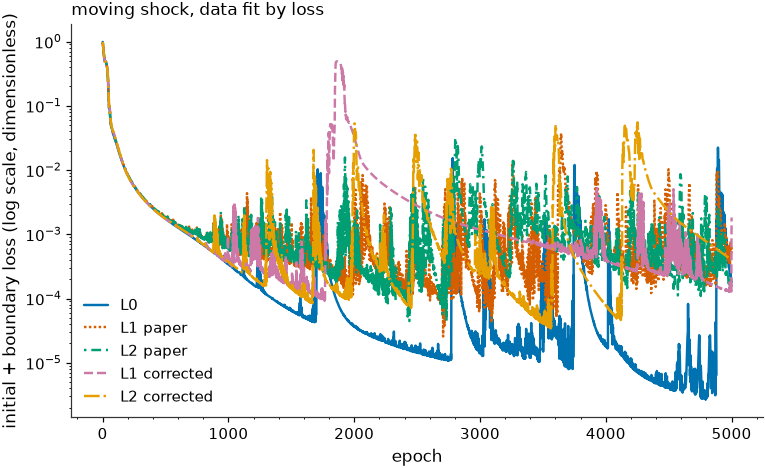

In [37]:
fig, ax = plt.subplots()
for name, history in histories.items():
    # Inicial + frontera: la única parte de la pérdida que significa lo mismo en las cinco.
    data_loss = np.array(history["initial"]) + np.array(history["boundary"])
    epochs = np.arange(1, len(data_loss) + 1)
    ax.semilogy(epochs, data_loss, linestyle=line_styles[name], label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("initial + boundary loss (log scale, dimensionless)")
ax.set_title("moving shock, data fit by loss")
ax.legend()
plt.show()

#### Figura 2: mapas y errores en t = T

**Figura 2.** Arriba: solución de cada pérdida en $t = T = 1$ con la misma escala $[0, 1]$; la línea punteada
blanca es el choque exacto en $x = 0.5$. Abajo: error absoluto con **la misma escala para las cinco**, así que un
panel más oscuro es de verdad un error menor. Si una pérdida sólo suaviza, su error es una franja delgada sobre la
línea; si mueve el choque, la franja es ancha.

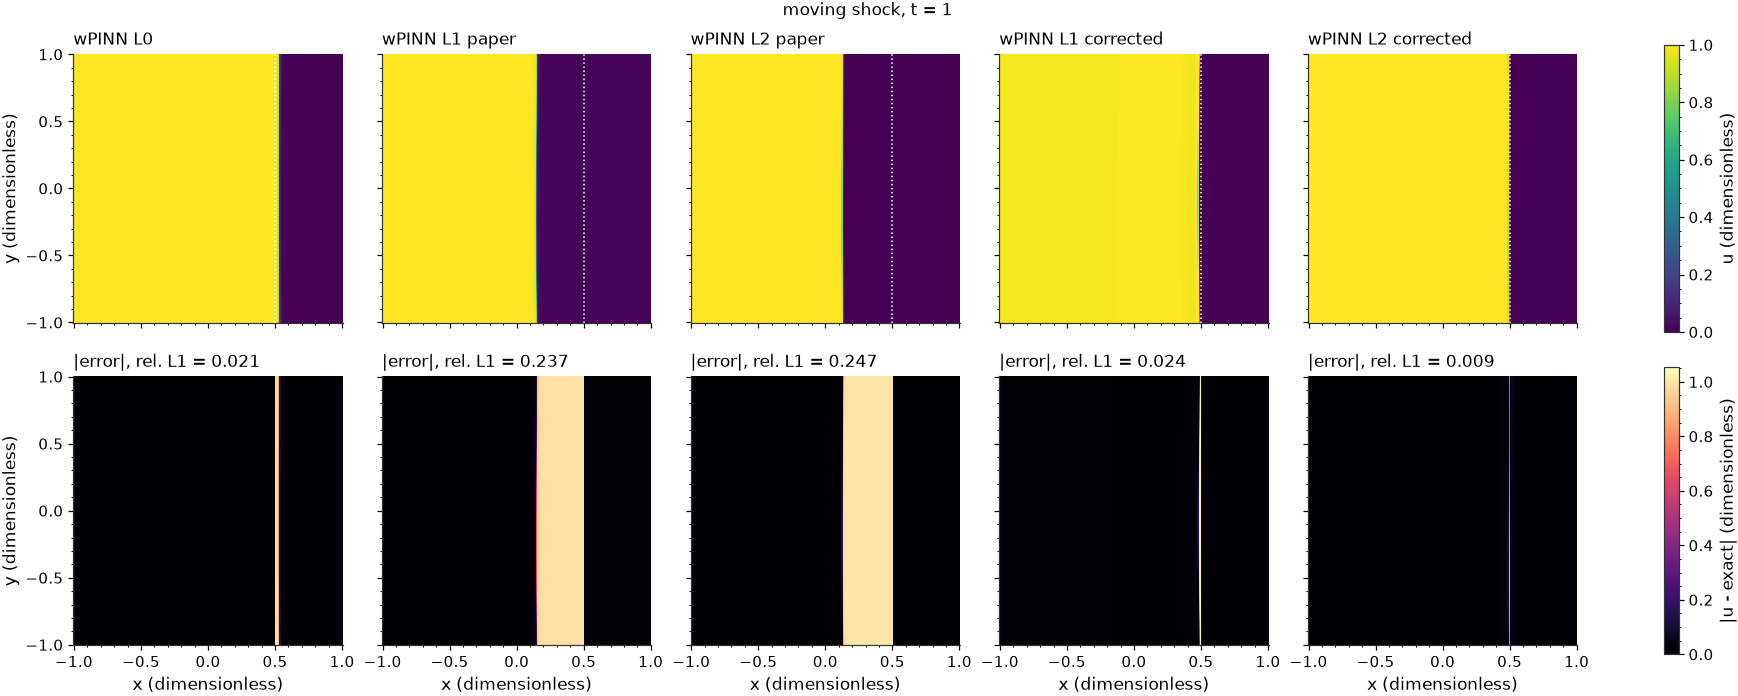

In [38]:
# Misma escala de error para las cinco: si cada panel tuviera la suya, la comparación mentiría.
error_max = max(error.max() for error in errors.values())

fig, axes = plt.subplots(2, len(networks), figsize=(16.0, 6.4), sharex=True, sharey=True)
for column, name in enumerate(networks):
    mesh = axes[0, column].pcolormesh(x_axis, y_axis, predictions[name], cmap="viridis", vmin=0, vmax=1, shading="auto")
    axes[0, column].axvline(shock_speed * T, color="white", linestyle=":", linewidth=1.0)
    axes[0, column].set_title(f"wPINN {name}")
    error_mesh = axes[1, column].pcolormesh(x_axis, y_axis, errors[name], cmap="magma", vmin=0, vmax=error_max, shading="auto")
    axes[1, column].set_title(f"|error|, rel. L1 = {summary[name]['l1']:.3f}")

fig.colorbar(mesh, ax=axes[0, :], label="u (dimensionless)")
fig.colorbar(error_mesh, ax=axes[1, :], label="|u - exact| (dimensionless)")
for ax in axes.flat:
    ax.set_aspect("equal")
for ax in axes[1, :]:
    ax.set_xlabel("x (dimensionless)")
for ax in axes[:, 0]:
    ax.set_ylabel("y (dimensionless)")
fig.suptitle(f"moving shock, t = {T:g}")
plt.show()

#### Figura 3: cortes en y = 0

**Figura 3.** Corte en $y = 0$ en cuatro tiempos. Como el dato no depende de $y$, este corte resume toda la
solución: la exacta (negro) es un escalón que va de $x = 0$ a $x = 0.5$. Se ve qué pérdida pone el choque en su
lugar y cuál lo suaviza más.

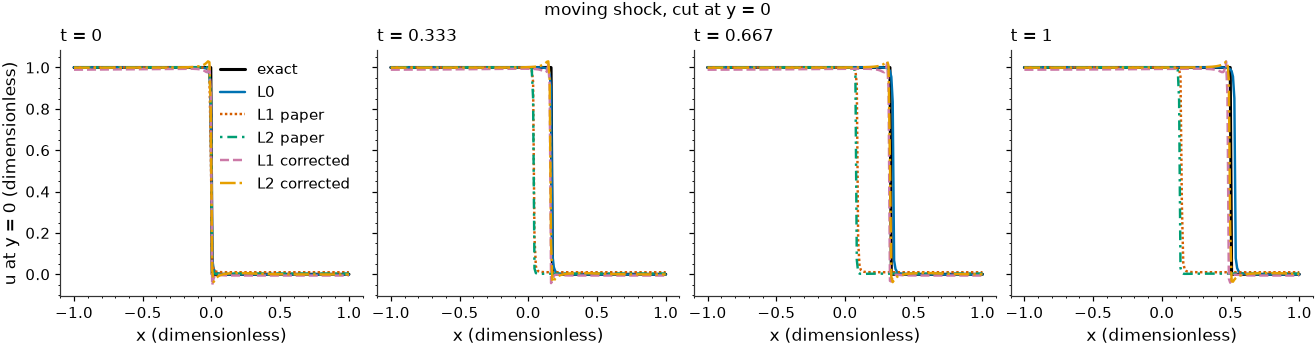

In [39]:
times = [0.0, T / 3, 2 * T / 3, T]
fig, axes = plt.subplots(1, 4, figsize=(12.0, 3.2), sharey=True)

for ax, time_value in zip(axes, times):
    ax.plot(x_axis, exact_solution(x_axis, time_value), color="black", linewidth=2.0, label="exact")
    for name, network in networks.items():
        u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, time_value))
        ax.plot(x_axis, u_cut, linestyle=line_styles[name], label=name)
    ax.set_title(f"t = {time_value:.3g}")
    ax.set_xlabel("x (dimensionless)")

axes[0].set_ylabel("u at y = 0 (dimensionless)")
axes[0].legend()
fig.suptitle("moving shock, cut at y = 0")
plt.show()

#### Figura 4: posición del choque en el tiempo

**Figura 4.** Posición del choque $x_s(t)$ (primer $x$ donde $u$ baja de 0.5 en $y = 0$) de cada pérdida. La
exacta (negro) es la recta $x_s = t/2$. **Una línea plana es un choque que no se mueve**; la pendiente es la
velocidad del choque y debería ser 1/2 en todo $[0, 1]$. Aquí se ve de inmediato si las del paper dejan el
choque quieto.

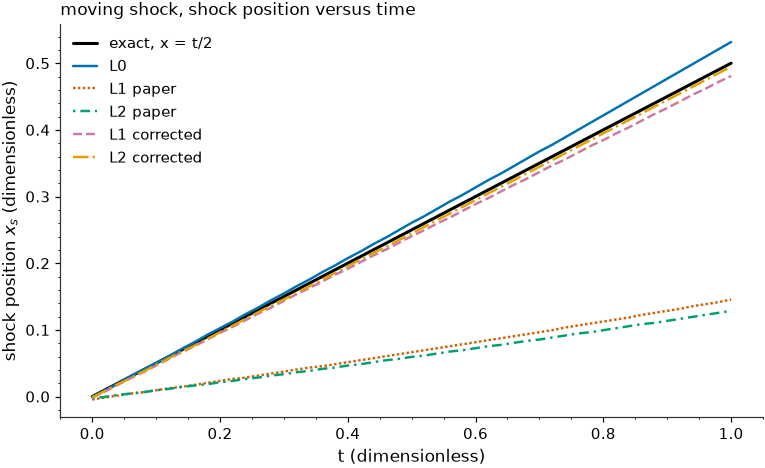

In [40]:
time_values = np.linspace(0.0, T, 51)

fig, ax = plt.subplots()
ax.plot(time_values, shock_speed * time_values, color="black", linewidth=2.0, label="exact, x = t/2")
for name, network in networks.items():
    positions = [shock_position(network, time_value) for time_value in time_values]
    ax.plot(time_values, positions, linestyle=line_styles[name], label=name)
ax.set_xlabel("t (dimensionless)")
ax.set_ylabel(r"shock position $x_s$ (dimensionless)")
ax.set_title("moving shock, shock position versus time")
ax.legend()
plt.show()